<a href="https://colab.research.google.com/github/bilalamove/Nabila-Tugas-SainData/blob/main/Nabila_PSD_M7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Penjualan per Bulan Tahun 2025**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('paket_a_transaksi_pos_2024_2025.csv')

# Menampilkan 5 data pertama
df.head()

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


**Jumlah transaksi tahun 2025**

In [3]:
# Mengubah tanggal menjadi datetime
df['tanggal'] = pd.to_datetime(
    df['tanggal'],
    format='mixed',
    dayfirst=True,
    errors='coerce'
)

# Mengubah harga satuan menjadi numerik
df['harga_satuan'] = pd.to_numeric(
    df['harga_satuan'].astype(str).str.replace(',', '.', regex=False),
    errors='coerce'
)

# Menyeragamkan status transaksi
df['status'] = df['status'].astype(str).str.strip().str.upper()

# Menghapus data yang tidak valid
df = df.dropna(
    subset=['tanggal', 'harga_satuan', 'jumlah', 'diskon_persen']
)

# Mengambil data tahun 2025
df_2025 = df[df['tanggal'].dt.year == 2025].copy()

# Menghitung total harga sebelum diskon
df_2025['total_harga'] = (
    df_2025['jumlah'] * df_2025['harga_satuan']
)

# Menghitung harga setelah diskon
df_2025['total_setelah_diskon'] = (
    df_2025['total_harga'] *
    (1 - df_2025['diskon_persen'] / 100)
)

print("Jumlah transaksi tahun 2025:", len(df_2025))

Jumlah transaksi tahun 2025: 2523


Preprocessing dilakukan untuk memastikan tanggal dan harga dapat dihitung dengan benar. Selanjutnya, data difilter agar hanya mengambil transaksi tahun 2025.

# Bagian 1 : Penjualan per Bulan Tahun 2025

Tujuannya untuk mengetahui jumlah pendapatan penjualan pada setiap bulan selama tahun 2025.

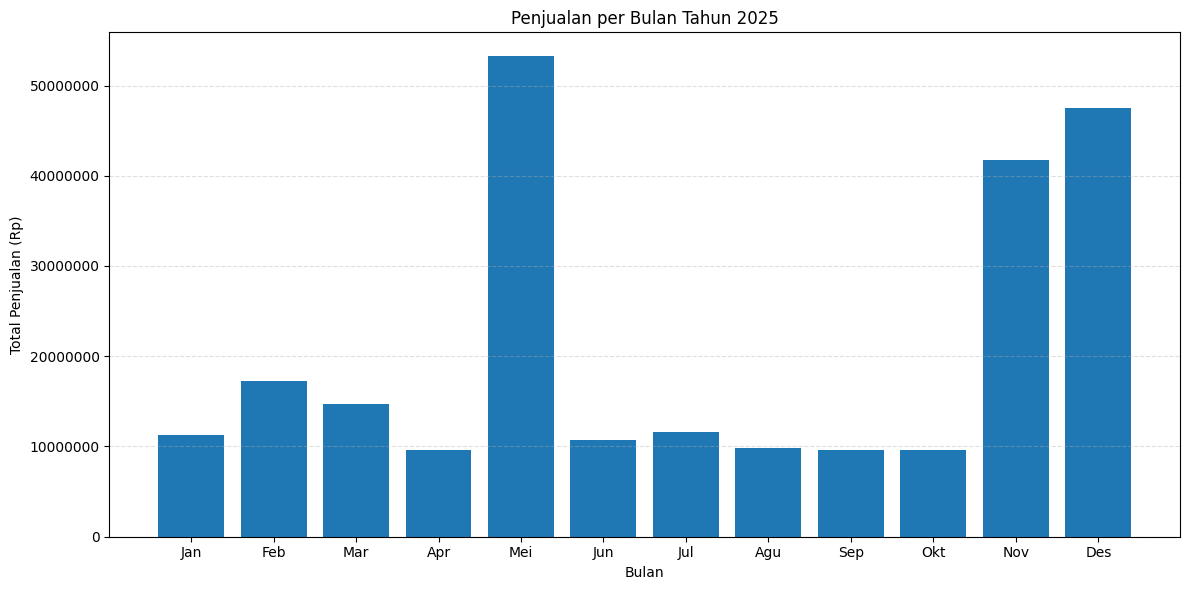

In [5]:
# Mengambil transaksi yang berhasil
data_selesai = df_2025[
    df_2025['status'] == 'SELESAI'
].copy()

# Mengambil bulan transaksi
data_selesai['bulan'] = data_selesai['tanggal'].dt.month

# Menghitung pendapatan per bulan
penjualan_bulanan = (
    data_selesai.groupby('bulan')['total_setelah_diskon']
    .sum()
    .reindex(range(1, 13), fill_value=0)
)

# Nama bulan
nama_bulan = [
    'Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'
]

# Membuat grafik
plt.figure(figsize=(12, 6))

plt.bar(
    nama_bulan, penjualan_bulanan.values
)

plt.title('Penjualan per Bulan Tahun 2025')
plt.xlabel('Bulan')
plt.ylabel('Total Penjualan (Rp)')

plt.ticklabel_format(
    axis='y', style='plain'
)

plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

**Cara membaca grafiknya:**
- Sumbu X menunjukkan bulan Januari sampai Desember.
- Sumbu Y menunjukkan total pendapatan penjualan.
- Batang tertinggi menunjukkan bulan dengan pendapatan terbesar.
- Batang terendah menunjukkan bulan dengan pendapatan terkecil.

**Analisis:** Penjualan tertinggi terjadi pada bulan Mei 2025, sedangkan penjualan terendah terjadi pada September 2025. Hal ini menunjukkan adanya perbedaan pendapatan yang cukup besar antarbulan.


# Bagian 2 : 10 Produk Terlaris Tahun 2025

Tujuannya untuk mengetahui 10 produk yang paling banyak terjual berdasarkan total jumlah barang yang berhasil dijual selama tahun 2025.

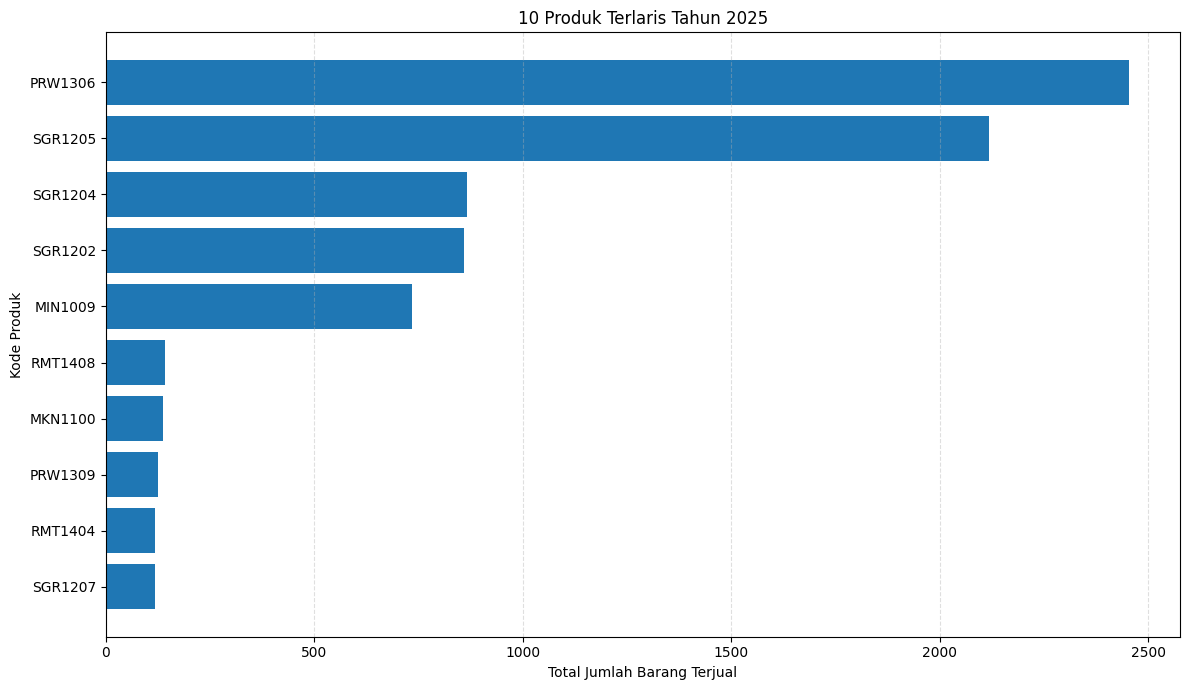

In [6]:
# Mengambil transaksi yang berhasil
data_produk = df_2025[
    df_2025['status'] == 'SELESAI'
]

# Menghitung total jumlah barang per produk
produk_terlaris = (
    data_produk.groupby('kode_produk')['jumlah']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Membuat grafik
plt.figure(figsize=(12, 7))

plt.barh(
    produk_terlaris.index, produk_terlaris.values
)

plt.title('10 Produk Terlaris Tahun 2025')
plt.xlabel('Total Jumlah Barang Terjual')
plt.ylabel('Kode Produk')

# Mengurutkan dari terbesar ke terkecil
plt.gca().invert_yaxis()

plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

**Cara membaca grafiknya:** Semakin panjang batang grafik, semakin banyak jumlah produk yang berhasil terjual. (Produk terlaris di sini dihitung berdasarkan jumlah unit barang, bukan berdasarkan besarnya pendapatan.)

**Analisis:** Produk PRW1306 merupakan produk dengan jumlah penjualan tertinggi, yaitu sebanyak 2.454 unit. Sementara itu, SGR1207 berada pada peringkat kesepuluh dengan 117 unit terjual.

# Bagian 3 : Proporsi Transaksi Berhasil vs Gagal/Cancel Tahun 2025

Tujuannya untuk mengetahui perbandingan jumlah transaksi berhasil dan transaksi yang tidak berhasil selama tahun 2025.

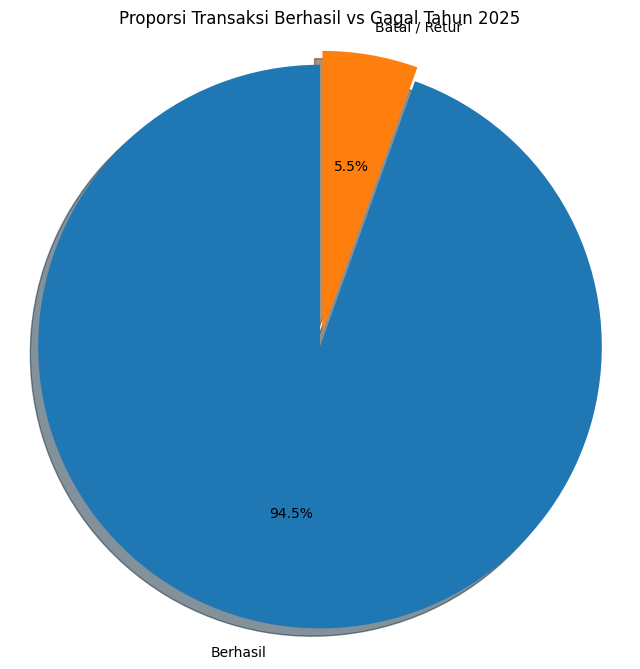

Transaksi berhasil: 2385
Transaksi batal/retur: 138


In [7]:
# Menghitung jumlah transaksi berdasarkan status
jumlah_berhasil = (
    df_2025['status'] == 'SELESAI'
).sum()

jumlah_gagal = (
    df_2025['status'].isin(['BATAL', 'RETUR'])
).sum()

# Menyiapkan data pie chart
label = ['Berhasil', 'Batal / Retur']

nilai = [
    jumlah_berhasil, jumlah_gagal
]

# Membuat pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    nilai, labels=label, autopct='%1.1f%%', startangle=90, explode=(0.05, 0), shadow=True
)

plt.title(
    'Proporsi Transaksi Berhasil vs Gagal Tahun 2025'
)

plt.axis('equal')
plt.show()

# Menampilkan jumlah transaksi
print("Transaksi berhasil:", jumlah_berhasil)
print("Transaksi batal/retur:", jumlah_gagal)

**Cara membaca grafiknya:**
- Bagian lingkaran terbesar menunjukkan proporsi transaksi berhasil.
- Bagian lingkaran lainnya menunjukkan transaksi batal atau retur.
- Persentase menunjukkan perbandingan masing-masing kategori terhadap keseluruhan transaksi tahun 2025.

**Analisis:** Sebagian besar transaksi pada tahun 2025 berhasil diselesaikan, yaitu sebesar 94,53%. Sementara itu, 5,47% merupakan transaksi batal atau retur. Hal ini menunjukkan bahwa mayoritas transaksi berhasil dilakukan.

# Bagian 4 : Hubungan Jumlah Beli dengan Diskon

Tujuannya untuk mengetahui apakah pemberian diskon memiliki hubungan dengan jumlah barang yang dibeli pelanggan.

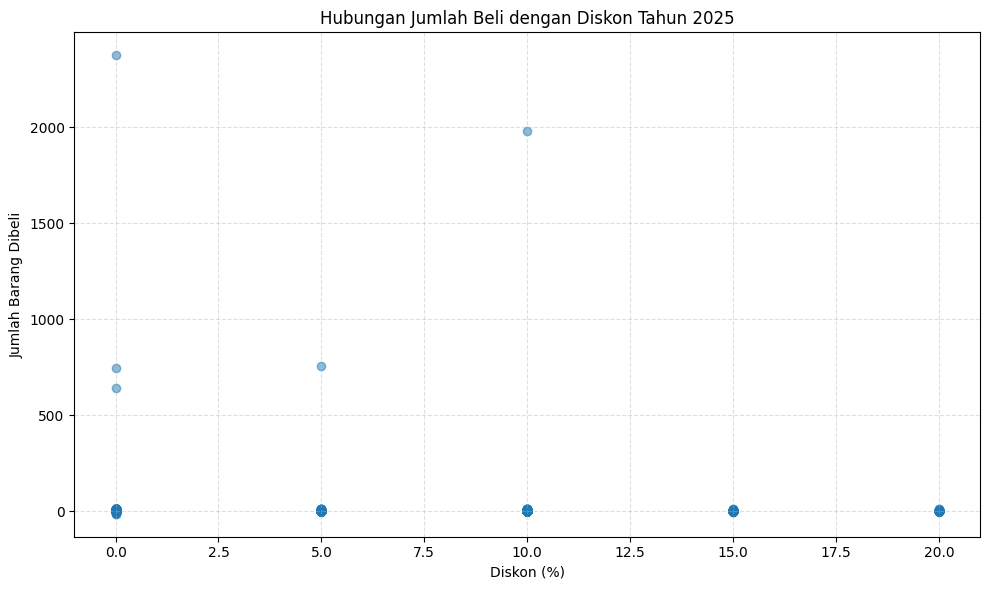

In [8]:
# Mengambil transaksi berhasil tahun 2025
data_diskon = df_2025[
    df_2025['status'] == 'SELESAI'
]

# Membuat scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    data_diskon['diskon_persen'], data_diskon['jumlah'], alpha=0.5
)

plt.title('Hubungan Jumlah Beli dengan Diskon Tahun 2025')
plt.xlabel('Diskon (%)')
plt.ylabel('Jumlah Barang Dibeli')

plt.grid(
    True, linestyle='--', alpha=0.4
)

plt.tight_layout()
plt.show()

**Cara membaca grafiknya:**
- Jika titik-titik cenderung naik dari kiri ke kanan, terdapat indikasi hubungan positif.
- Jika titik-titik cenderung turun, terdapat indikasi hubungan negatif.
- Jika titik-titik menyebar tanpa pola yang jelas, hubungan kedua variabel cenderung lemah.

**Analisis:** Nilai korelasi sebesar 0,0077 menunjukkan bahwa hubungan linear antara jumlah barang yang dibeli dengan persentase diskon hampir tidak ada. Artinya, berdasarkan dataset ini, peningkatan diskon tidak menunjukkan hubungan linear yang berarti dengan peningkatan jumlah pembelian.